# Benford's law on meter data

All statistics use **training clients only** (`data/splits/train_ids.csv`). The work is done by
`src/features/benford_analysis.py` (`python run.py benford`); this notebook calls it and shows the outputs.

* MAD is the mean absolute difference between observed and Benford digit shares. Nigrini's conformity bands:
  first digit close <= 0.006, acceptable <= 0.012, marginal <= 0.015, above that nonconformity;
  first two digits close <= 0.0012, acceptable <= 0.0018, marginal <= 0.0022.
* With millions of invoices the chi-square test rejects any tiny deviation, so the MAD band is the measure to read.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
from IPython.display import Image, display

from src.features import benford_analysis

pd.set_option("display.float_format", "{:.4g}".format)
out = benford_analysis.run()

## 1. First digit of positive per-invoice consumption, fraud vs non-fraud

,class,n,chi2,dof,p_value,mad,nigrini_band
0,Non-fraud,2952305,6.992e+04,8,0,0.01573,nonconformity
1,Fraud,252464,1472,8,0,0.007463,acceptable


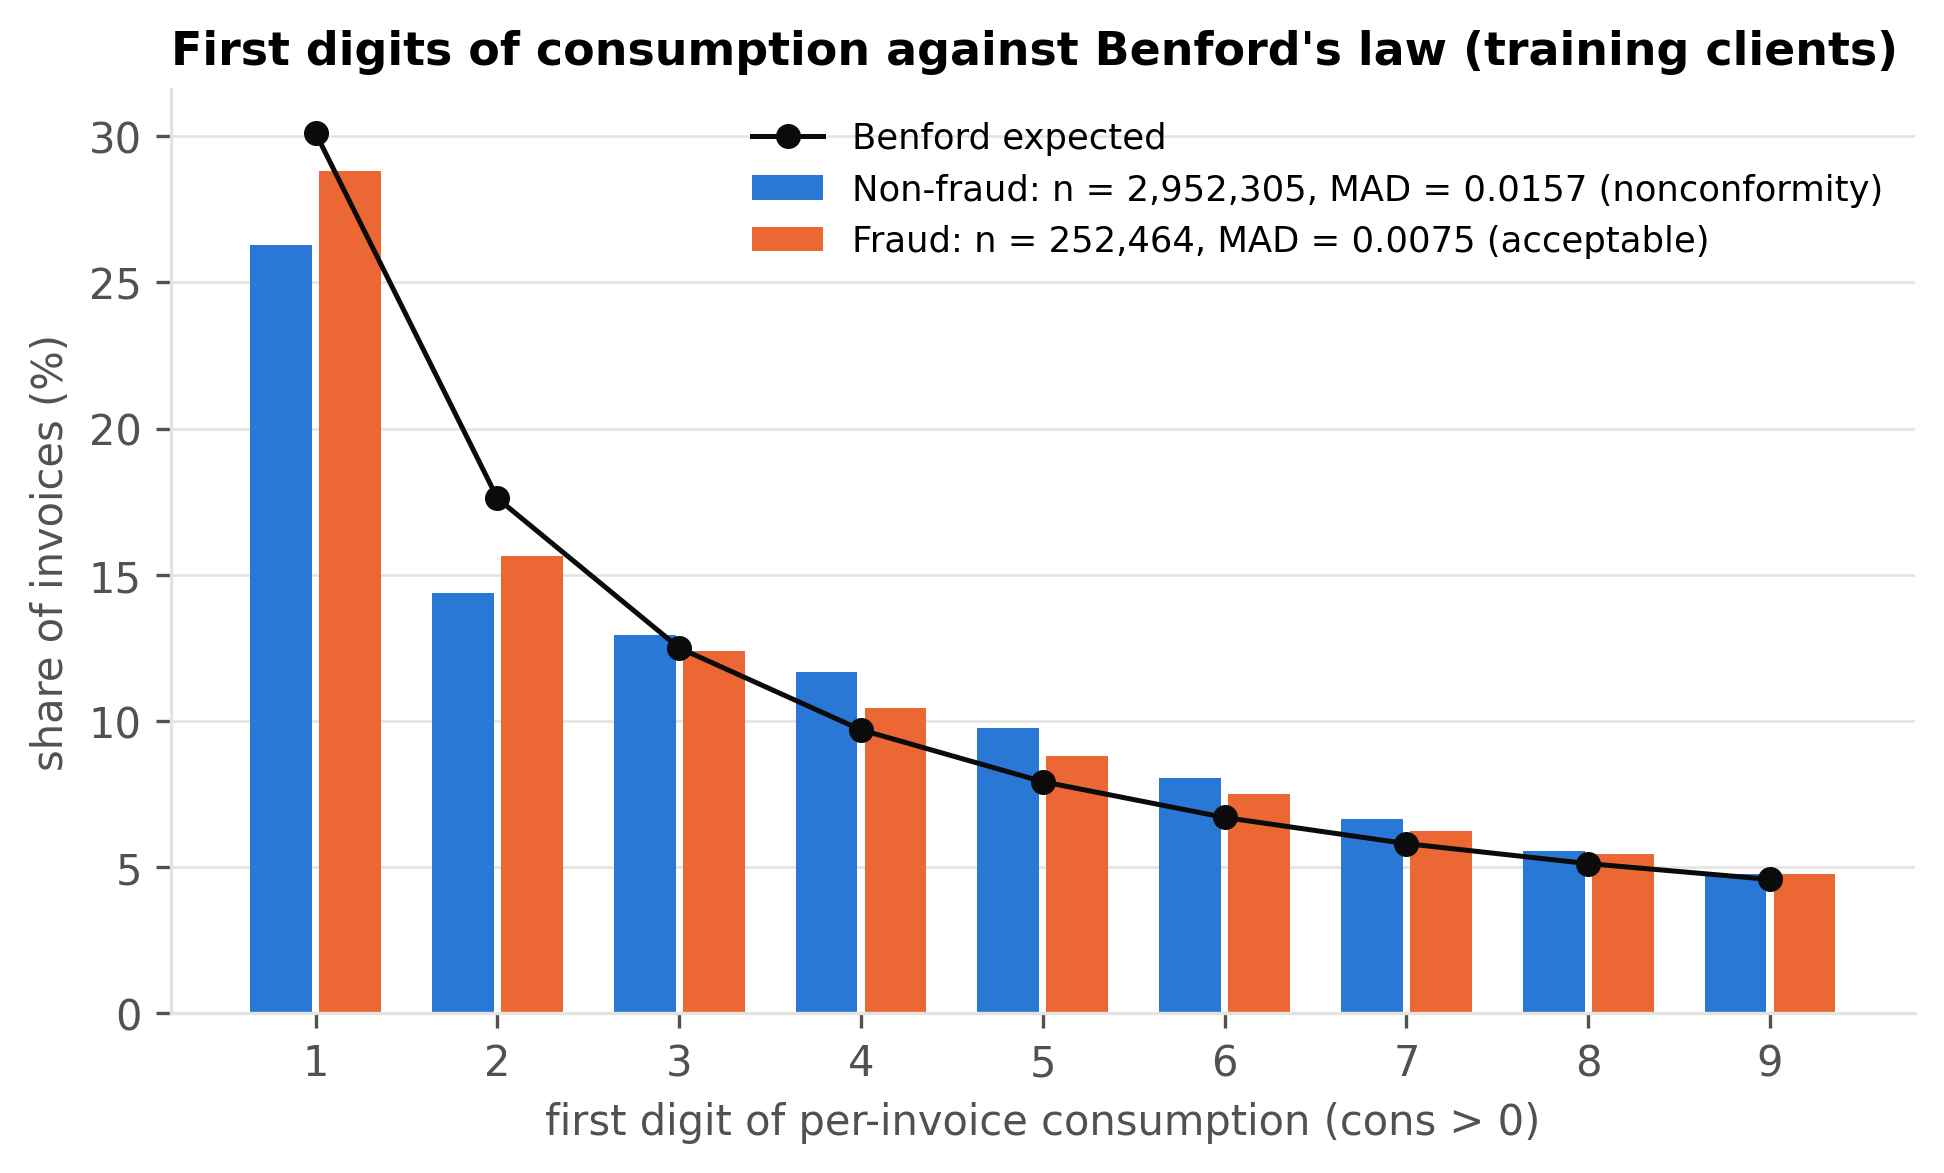

In [2]:
display(out["by_class"])
Image("results/figures/benford_first_digit.png", width=750)

## 2. Per district, ranked by MAD

`class = All` pools both classes. Groups with fewer than 1,000 positive invoices are left out (none are).

In [3]:
out["district"]

,rank,district,n,chi2,dof,p_value,mad,nigrini_band,class
0,1,63,695286,2.621e+04,8,0,0.02008,nonconformity,Non-fraud
1,2,63,766870,2.582e+04,8,0,0.01897,nonconformity,All
2,3,62,898512,2.893e+04,8,0,0.01829,nonconformity,Non-fraud
3,4,62,967962,2.904e+04,8,0,0.01765,nonconformity,All
4,5,60,670593,9611,8,0,0.0122,marginal,Non-fraud
5,6,69,687914,9631,8,0,0.0119,acceptable,Non-fraud
6,7,60,705198,9551,8,0,0.01185,acceptable,All
7,8,69,764739,9788,8,0,0.01138,acceptable,All
8,9,62,69450,616.6,8,6.185e-128,0.009382,acceptable,Fraud
9,10,63,71584,518.6,8,7.016e-107,0.008215,acceptable,Fraud


## 3. Drill-down on the worst group

The district x class group with the largest first-digit MAD, first digit then first two digits (10 to 99),
as in the lecture's cheque example.

,test,n,chi2,dof,p_value,mad,nigrini_band,district,class
0,first digit,695286,2.621e+04,8,0,0.02008,nonconformity,63,Non-fraud
1,first two digits,680602,2.887e+04,89,0,0.002019,marginal,63,Non-fraud


,digit,observed,expected,difference
43,44,0.01281,0.00976,0.003052
46,47,0.01211,0.009143,0.002965
41,42,0.01317,0.01022,0.002953
44,45,0.01243,0.009545,0.002885
45,46,0.01221,0.00934,0.002865
49,50,0.01146,0.0086,0.002862
42,43,0.01281,0.009984,0.002829
47,48,0.01174,0.008955,0.00278


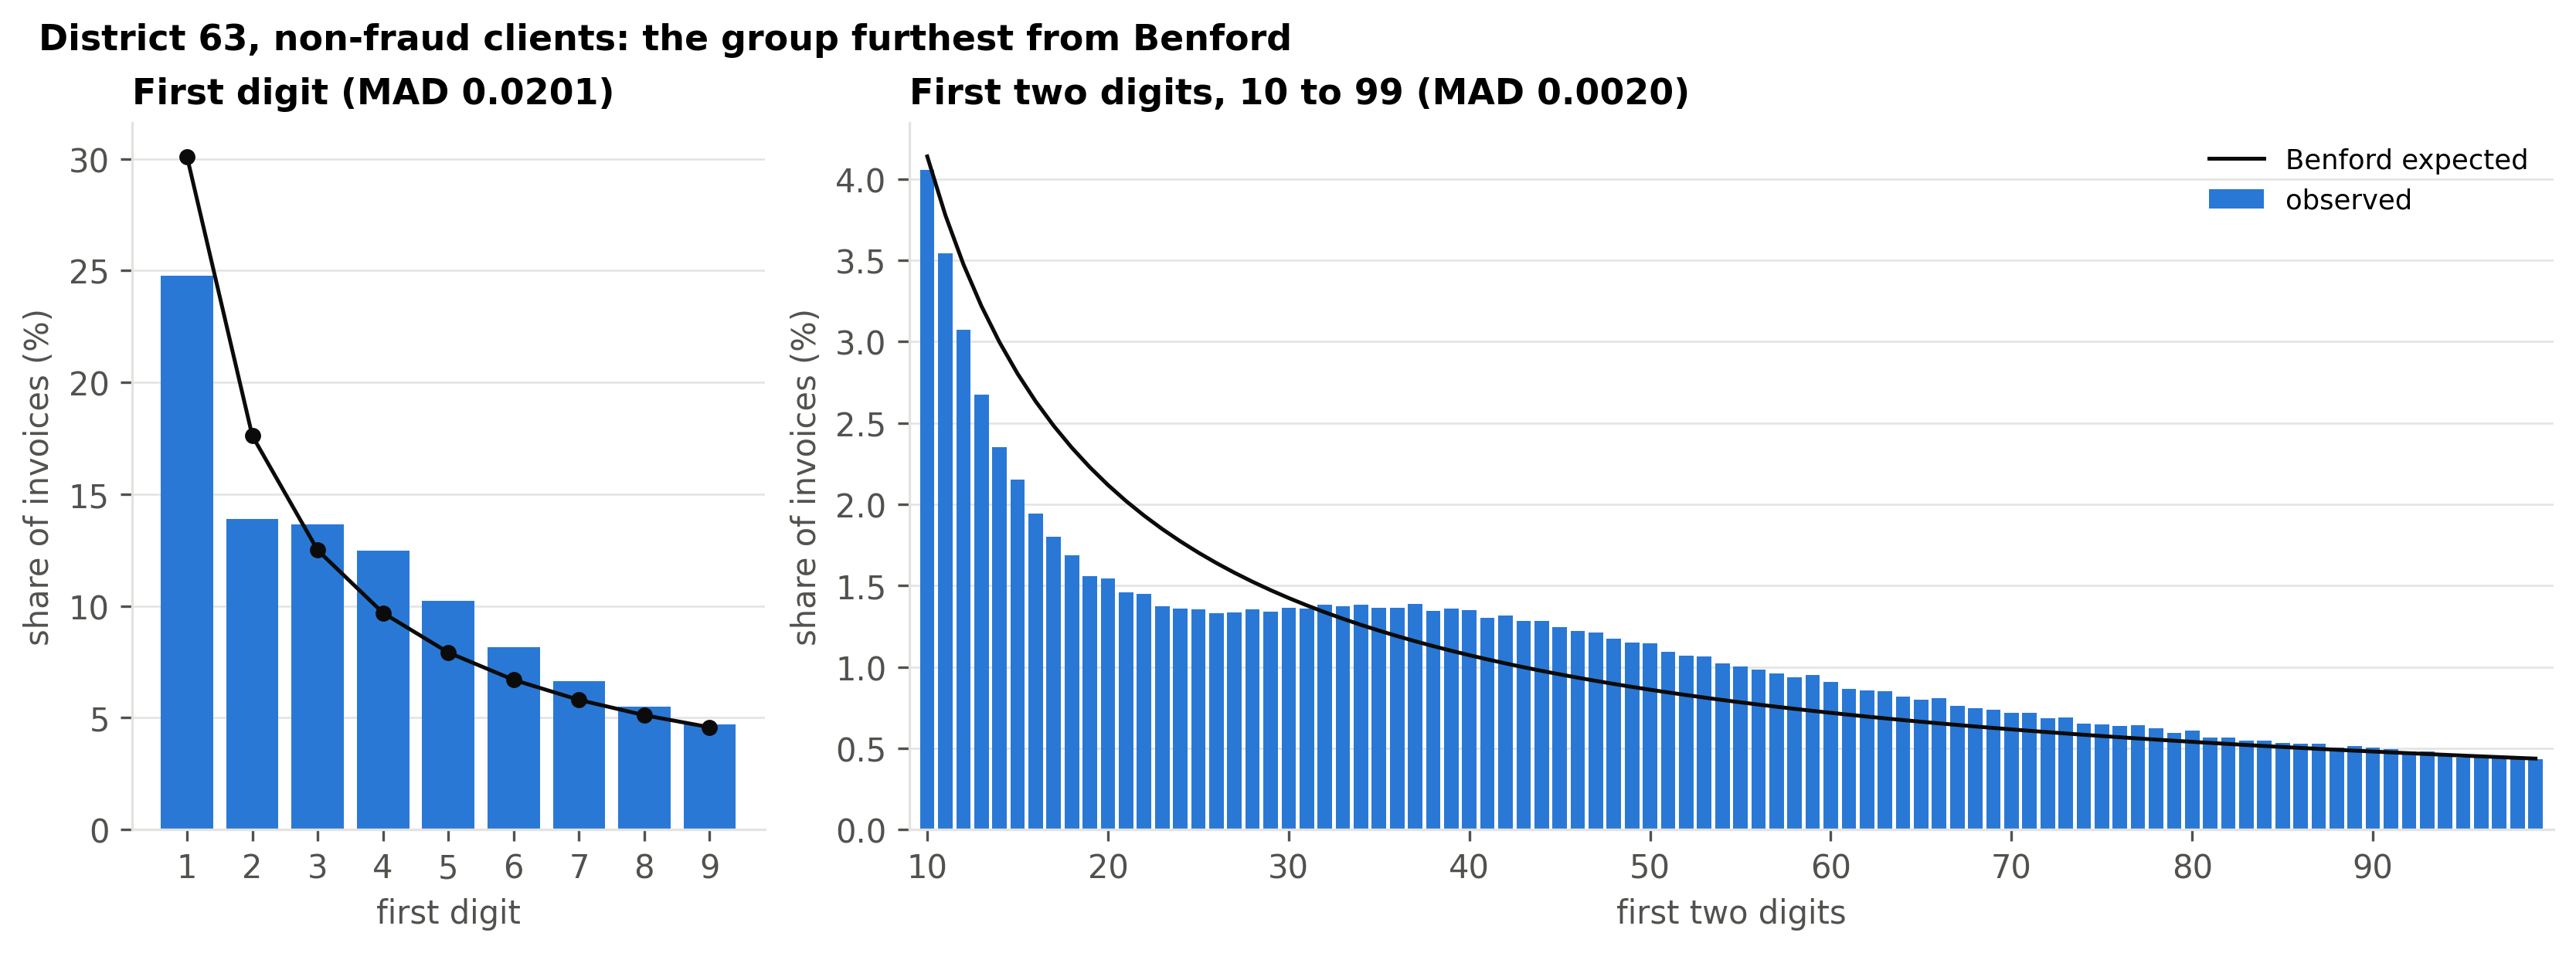

In [4]:
display(out["drill"])
two = out["drill_detail"].query("test == 'first two digits'")
display(two.nlargest(8, "difference")[["digit", "observed", "expected", "difference"]])
Image("results/figures/benford_two_digit.png", width=900)

## 4. Last digit of `new_index`

An honest meter reading ends in 0 or 5 about 20% of the time; readings that are estimated or typed in by hand
tend to be rounded. Readings of 0 are left out; the second subset also drops zero-consumption bills, whose
index simply repeats.

In [5]:
out["last_digit"][["subset", "class", "n", "share_0_or_5", "ci_low", "ci_high", "binom_p_value"]]

,subset,class,n,share_0_or_5,ci_low,ci_high,binom_p_value
0,new_index > 0,Non-fraud,3150148,0.2119,0.2115,0.2124,0
1,new_index > 0,Fraud,271592,0.2115,0.2099,0.213,1.132e-49
2,new_index > 0 and cons > 0,Non-fraud,2951927,0.2125,0.2121,0.213,0
3,new_index > 0 and cons > 0,Fraud,252436,0.2113,0.2097,0.2129,5.197e-45


## 5. Numbers behind the caveats

In [6]:
out["caveats"]

,statistic,value
0,positive invoices,3.205e+06
1,share with tariff level 1 full (level 2+ > 0),0.1651
2,median positive invoices per client,27
3,share of clients below the F7 minimum of 20,0.3916
4,expected MAD of a perfect Benford sample of th...,0.0452
5,expected MAD of a perfect Benford sample of 20,0.05251


## What it shows

1. Neither class follows Benford closely, and the non-fraud invoices deviate *more* (MAD 0.0157, nonconformity)
   than the fraud invoices (MAD 0.0075, acceptable): both have too few bills starting with 1 or 2 and too many
   starting with 4 to 6, so a large first-digit deviation is not a fraud marker in this data.
2. The deviation is a district effect: districts 63 and 62 are in nonconformity (MAD 0.020 and 0.018 for their
   non-fraud clients), districts 60 and 69 are acceptable or marginal, and in every district the fraud group sits
   closer to Benford than the non-fraud group.
3. In the worst group (district 63, non-fraud) the two-digit test shows too few values from 10 to 30 and a broad
   excess from about 31 to 60 (largest at 42 to 50) rather than spikes at particular values, which points to many households billed in the same narrow consumption
   range (a few hundred units per 4-month bill) rather than to invented numbers; meter readings end in 0 or 5
   about 21% of the time in both classes, only slightly above the 20% expected.
4. Caveats: consumption does not span the several orders of magnitude Benford needs, and tariff level 1 is
   capped per billing period, so 17% of positive bills start at a band limit; a client has a median of 27
   positive bills, for which even a perfect Benford sample has an expected MAD of 0.045 (nonconformity), so
   per-client MAD is mostly noise; and with millions of invoices every chi-square test is significant, so only
   the size of the deviation (MAD) is informative.